In [8]:
#import library
import numpy as np #linear algebra
import pandas as pd #data processing,csv file I/O
import datetime as dt

#for data visualization
import matplotlib.pyplot as plt
import seaborn as sns


#for Machine learning algorithm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_excel('Online Retail.xlsx')

#### **Explore + clean the data**

In [9]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


#### Check and clean missing data

In [11]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [12]:
df = df.dropna(subset=["CustomerID"])

In [13]:
df.isnull().sum().sum()

np.int64(0)

#### check & clean duplicate data

In [14]:
df.duplicated().sum()

np.int64(5225)

In [15]:
df = df.drop_duplicates()

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,401604.000000,401604,401604.000000,401604.000000
mean,12.183273,2011-07-10 12:08:23.848567,3.474064,15281.160818
min,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000
25%,2.000000,2011-04-06 15:02:00,1.250000,13939.000000
50%,5.000000,2011-07-29 15:40:00,1.950000,15145.000000
75%,12.000000,2011-10-20 11:58:30,3.750000,16784.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,250.283037,NaN,69.764035,1714.006089


In [18]:
df = df[(df['Quantity']>0) & (df['UnitPrice']>0)]
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,392692.000000,392692,392692.000000,392692.000000
mean,13.119702,2011-07-10 19:13:07.771892,3.125914,15287.843865
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000
25%,2.000000,2011-04-07 11:12:00,1.250000,13955.000000
50%,6.000000,2011-07-31 12:02:00,1.950000,15150.000000
75%,12.000000,2011-10-20 12:53:00,3.750000,16791.000000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000
std,180.492832,NaN,22.241836,1713.539549


In [19]:
df.shape

(392692, 8)

## Let's Make Cohart Analysis

In [20]:
def get_month(x): return dt.datetime(x.year,x.month,1)
df['InvoiceMonth']=df['InvoiceDate'].apply(get_month)
grouping = df.groupby('CustomerID')['InvoiceMonth']
df['CohartMonth']= grouping.transform('min')
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceMonth,CohartMonth
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,2011-12-01,2011-08-01
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011-12-01,2011-08-01
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011-12-01,2011-08-01
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011-12-01,2011-08-01
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011-12-01,2011-08-01


In [21]:
def get_month_int(dframe,column):
    year = dframe[column].dt.year
    month = dframe[column].dt.month
    day = dframe[column].dt.day
    return  year, month, day

invoice_year,invoice_month,_ = get_month_int(df,'InvoiceMonth')
cohart_year, cohart_month,_ = get_month_int(df,'CohartMonth')

year_diff = invoice_year - cohart_year
month_diff= invoice_month - cohart_month

df['CohartIndex'] = year_diff * 12 + month_diff + 1

In [22]:
#Count Monthly active customers from each cohart
grouping = df.groupby(['CohartMonth', 'CohartIndex'])
cohart_data = grouping['CustomerID'].apply(pd.Series.nunique)

#Return number of unique elements in the object
cohart_data  = cohart_data.reset_index()
cohart_counts = cohart_data.pivot(index='CohartMonth', columns='CohartIndex',values='CustomerID')
cohart_counts

CohartIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohartMonth,,,,,,,,,,,,,
2010-12-01,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02-01,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03-01,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04-01,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05-01,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06-01,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-01,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08-01,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### **Retention Rate Table**

In [23]:
# Retention Table
cohart_size = cohart_counts.iloc[:,0]
retention = cohart_counts.divide(cohart_size,axis=0)
retention.round(3) * 100 

CohartIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohartMonth,,,,,,,,,,,,,
2010-12-01,100.0,36.6,32.3,38.4,36.3,39.8,36.3,34.9,35.4,39.5,37.4,50.3,26.6
2011-01-01,100.0,22.1,26.6,23.0,32.1,28.8,24.7,24.2,30.0,32.6,36.5,11.8,NaN
2011-02-01,100.0,18.7,18.7,28.4,27.1,24.7,25.3,27.9,24.7,30.5,6.8,NaN,NaN
2011-03-01,100.0,15.0,25.2,19.9,22.3,16.8,26.8,23.0,27.9,8.6,NaN,NaN,NaN
2011-04-01,100.0,21.3,20.3,21.0,19.7,22.7,21.7,26.0,7.3,NaN,NaN,NaN,NaN
2011-05-01,100.0,19.0,17.3,17.3,20.8,23.2,26.4,9.5,NaN,NaN,NaN,NaN,NaN
2011-06-01,100.0,17.4,15.7,26.4,23.1,33.5,9.5,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-01,100.0,18.1,20.7,22.3,27.1,11.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08-01,100.0,20.7,24.9,24.3,12.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


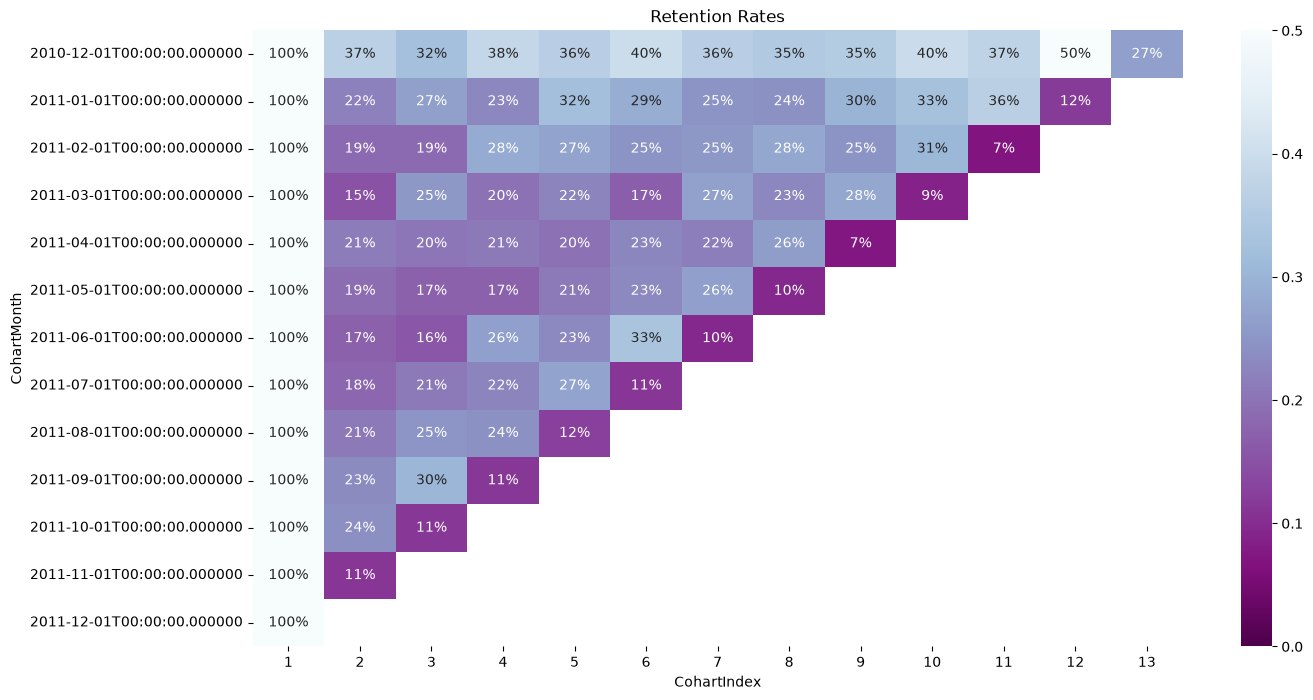

In [24]:
#Build the Heatmap
plt.figure(figsize=(15,8))
plt.title('Retention Rates')
sns.heatmap(data=retention,annot=True,fmt='.0%',vmin=0.0,vmax=0.5,cmap="BuPu_r")
plt.show()

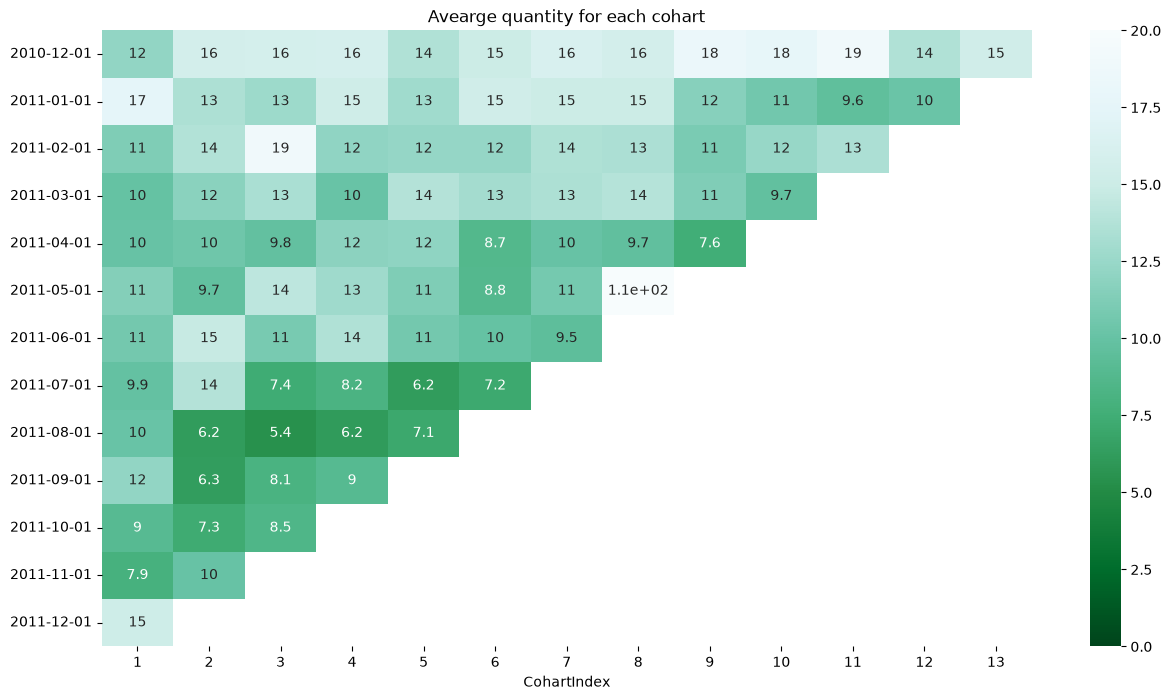

In [25]:
#Average quantity for each cohart
grouping = df.groupby(['CohartMonth', 'CohartIndex'])
cohart_data = grouping['Quantity'].mean()
cohart_data  = cohart_data.reset_index()
avg_quantity = cohart_data.pivot(index='CohartMonth', columns='CohartIndex',values='Quantity')
avg_quantity.round(1)
avg_quantity.index = avg_quantity.index.date

#Build the Heatmap
plt.figure(figsize=(15,8))
plt.title('Avearge quantity for each cohart')
sns.heatmap(data=avg_quantity,annot=True,vmin=0.0,vmax=20,cmap="BuGn_r")
plt.show()

### RFM

In [26]:
# New Total sum column
df['TotalSum']=df['UnitPrice']*df['Quantity']

#Data prepartion steps
print('Min Invoice date:',df.InvoiceDate.dt.date.min(),'max invoice date:',df.InvoiceDate.dt.date.max())

df.head()

Min Invoice date: 2010-12-01 max invoice date: 2011-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceMonth,CohartMonth,CohartIndex,TotalSum
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01,2010-12-01,1,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,2010-12-01,1,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01,2010-12-01,1,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,2010-12-01,1,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,2010-12-01,1,20.34


In [27]:
snapshot_data = df['InvoiceDate'].max() + dt.timedelta(days=1)
snapshot_data


#the last day of purchase in total is 09dec, 2011.to calculate the day periods
#let's set one day after the last one, or 10 dec as a sanapshot. we will cound the diff days with snapshot dat

Timestamp('2011-12-10 12:50:00')

In [28]:
# calculate RFM metrics
rfm = df.groupby(['CustomerID']).agg({'InvoiceDate': lambda x : (snapshot_data - x.max()).days,
                                      'InvoiceNo': 'count','TotalSum':'sum'})
#function lambda : it gives  the number of days betweeen hypothetical today and the last transaction

#rename columns
rfm.rename(columns={'InvoiceDate':'Recency','InvoiceNo':'Frequency','TotalSum':'MonetaryValue'
                    },inplace=True)

#final rfm values
rfm.head()

,Recency,Frequency,MonetaryValue
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,182,4310.00
12348.0,75,31,1797.24
12349.0,19,73,1757.55
12350.0,310,17,334.40


In [29]:
# building RFM segments
r_labels = range(4,0,-1)
f_labels = range(1,5)
m_labels = range(1,5)
r_quartiles = pd.qcut(rfm['Recency'], q=4, labels=r_labels)
f_quartiles = pd.qcut(rfm['Frequency'], q=4, labels=f_labels)
m_quartiles = pd.qcut(rfm['MonetaryValue'], q=4, labels=m_labels)
rfm = rfm.assign(R=r_quartiles, F=f_quartiles,M=m_quartiles)

def add_rfm(x): return str(x['R']) +str(x['F']) + str(x['M'])
rfm['rfm_segment'] = rfm.apply(add_rfm,axis=1)
rfm['rfm_score'] = rfm[['R','F','M']].sum(axis=1)

rfm.head()

,Recency,Frequency,MonetaryValue,R,F,M,rfm_segment,rfm_score
CustomerID,,,,,,,,
12346.0,326,1,77183.60,1,1,4,1.01.04.0,6
12347.0,2,182,4310.00,4,4,4,4.04.04.0,12
12348.0,75,31,1797.24,2,2,4,2.02.04.0,8
12349.0,19,73,1757.55,3,3,4,3.03.04.0,10
12350.0,310,17,334.40,1,1,2,1.01.02.0,4


### Analyzing RFM Segments

In [30]:
rfm.groupby(['rfm_segment']).size().sort_values(ascending=False)[:5]

rfm_segment
4.04.04.0    450
1.01.01.0    381
3.04.04.0    217
1.02.02.0    206
2.01.01.0    179
dtype: int64

Summary metrics per RFM score

In [31]:
rfm.groupby(['rfm_score']).agg({'Recency':'mean','Frequency':'mean','MonetaryValue':['mean','count']}).round(1)

Recency Frequency MonetaryValue      
             mean      mean          mean count
rfm_score                                      
3           260.7       8.2         157.4   381
4           177.2      13.6         240.0   388
5           152.9      21.2         366.6   518
6            95.9      27.9         820.8   457
7            79.6      38.0         758.1   463
8            64.1      56.0         987.3   454
9            45.9      78.7        1795.1   414
10           32.4     110.5        2056.4   426
11           21.3     186.9        4062.0   387
12            7.2     367.8        9285.9   450

use RFM score to group customers into gold,silver and bronze segments:

In [32]:
def segments(df):
    if df['rfm_score'] > 9 :
        return 'gold'
    elif (df['rfm_score'] >5) and (df['rfm_score'] <=9):
        return 'silver'
    else:
        return 'bronze'

rfm['General_Segment'] =  rfm.apply(segments,axis=1)

rfm.groupby(['General_Segment']).agg({'Recency':'mean','Frequency':'mean','MonetaryValue':['mean','count']}).round(1)

Recency Frequency MonetaryValue      
                   mean      mean          mean count
General_Segment                                      
bronze            192.2      15.1         266.5  1287
gold               20.1     225.6        5246.8  1263
silver             72.0      49.4        1072.4  1788

## Data Pre-Processing for Kmeans Clustering

In [33]:
rfm_rfm = rfm[['Recency', 'Frequency','MonetaryValue']]
print(rfm_rfm.describe())

           Recency    Frequency  MonetaryValue
count  4338.000000  4338.000000    4338.000000
mean     92.536422    90.523744    2048.688081
std     100.014169   225.506968    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000    17.000000     306.482500
50%      51.000000    41.000000     668.570000
75%     142.000000    98.000000    1660.597500
max     374.000000  7676.000000  280206.020000


from this table, we find this problem : Mean Variance are not equal

solution:scaling variables by using a scaler from scikitlearn library

C:\Users\Dhanush\AppData\Local\Temp\ipykernel_18588\2140661089.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  plt.subplot(3,1,1); sns.distplot(rfm.Recency, label='Recency')
C:\Users\Dhanush\AppData\Local\Temp\ipykernel_18588\2140661089.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  plt.subplot(3,1,2); sns.distp

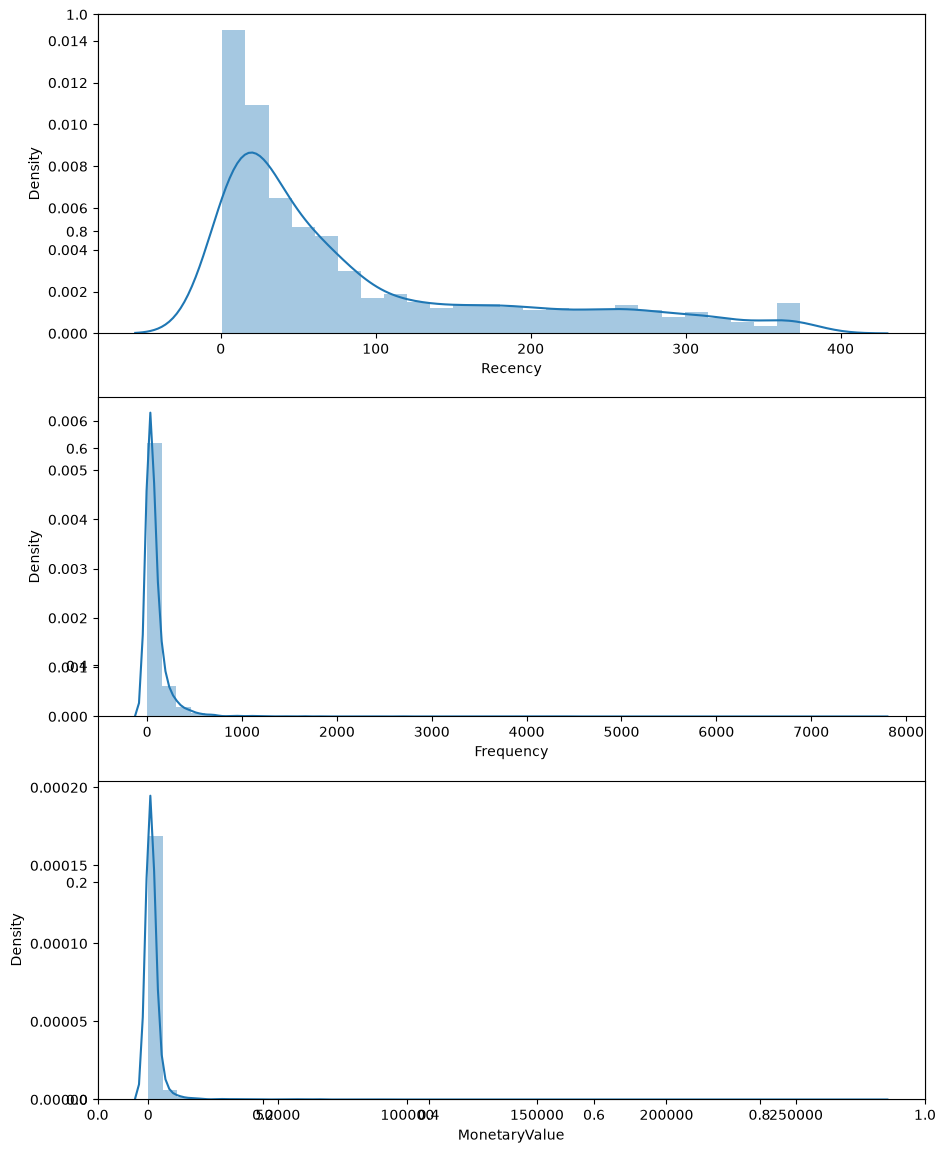

In [35]:
#plot the distribution
f,ax=plt.subplots(figsize=(10,12))
plt.subplot(3,1,1); sns.distplot(rfm.Recency, label='Recency')
plt.subplot(3,1,2); sns.distplot(rfm.Frequency, label='Frequency')
plt.subplot(3,1,3); sns.distplot(rfm.MonetaryValue, label='MonetaryValues')
plt.style.use('fivethirtyeight')
plt.tight_layout()
plt.show()

also,there is another problem: Unsymmetric distribution of variance(data skewed)

solution :Logarthmic Transformation (postive values only ) will manage skewness

C:\Users\Dhanush\AppData\Local\Temp\ipykernel_18588\444506422.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  plt.subplot(3,1,1); sns.distplot(rfm_log.Recency, label='Recency')
C:\Users\Dhanush\AppData\Local\Temp\ipykernel_18588\444506422.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  plt.subplot(3,1,2); sns.dis

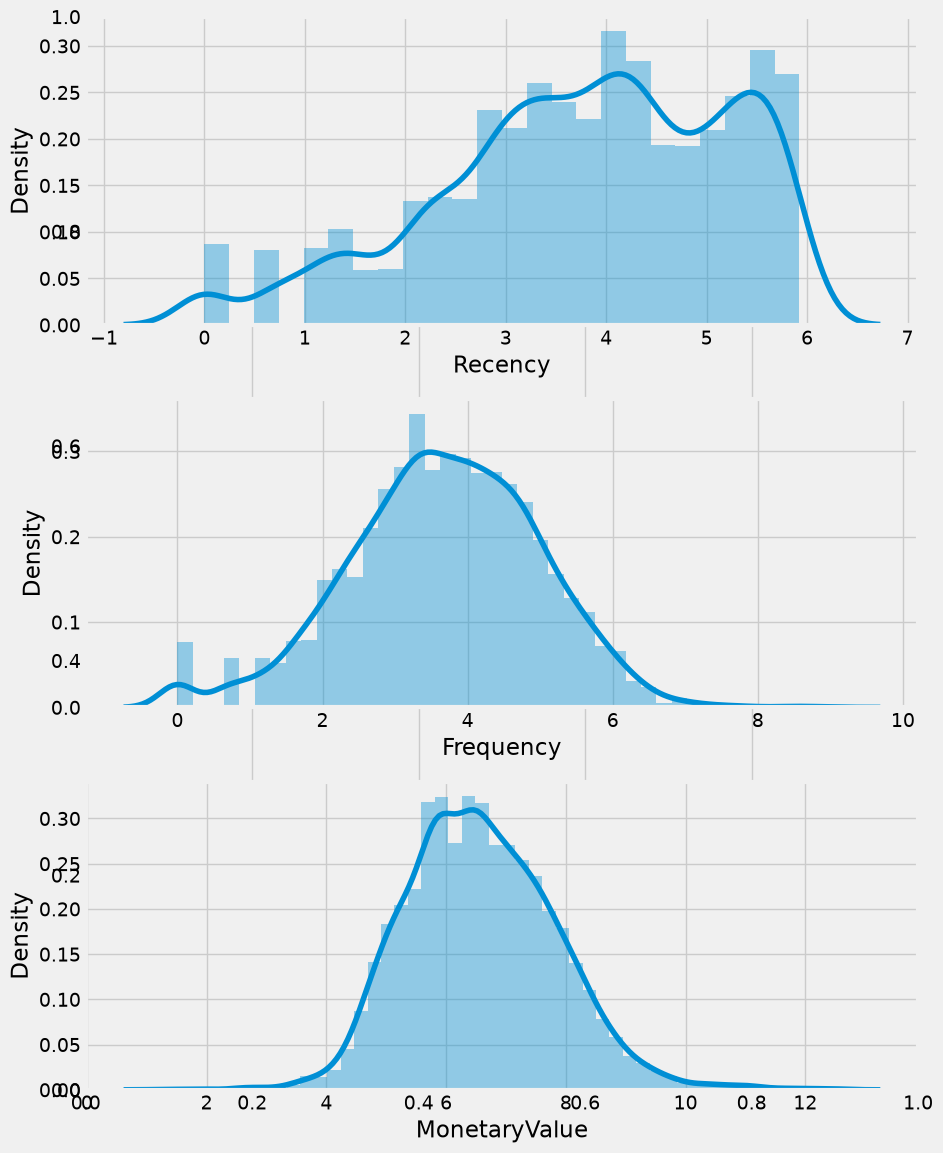

In [36]:
#Unskew the data with log Transformation
rfm_log = rfm[['Recency','Frequency','MonetaryValue']].apply(np.log, axis=1).round(3)
#or rfm_log = np.log(rfm_rfm)

#plot the distribution
f,ax=plt.subplots(figsize=(10,12))
plt.subplot(3,1,1); sns.distplot(rfm_log.Recency, label='Recency')
plt.subplot(3,1,2); sns.distplot(rfm_log.Frequency, label='Frequency')
plt.subplot(3,1,3); sns.distplot(rfm_log.MonetaryValue, label='MonetaryValues')
plt.style.use('fivethirtyeight')
plt.tight_layout()
plt.show()

### Implementation of KMeans CLustering

#### **1.Data Pre-Processing**

In [37]:
#normalise the variables StandardScalar
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(rfm_log)
#store it separately for clustering
rfm_normalized = scaler.transform(rfm_log)

#### **2.choosing a number of cluster**

-Methods to define the number of clusters
* Visual methods-elbow criterion<br>
* Mathematical methods-silhoutte coefficient<br>
*  Experimentation and Interpretation<br>

#### *elbow criterion method*



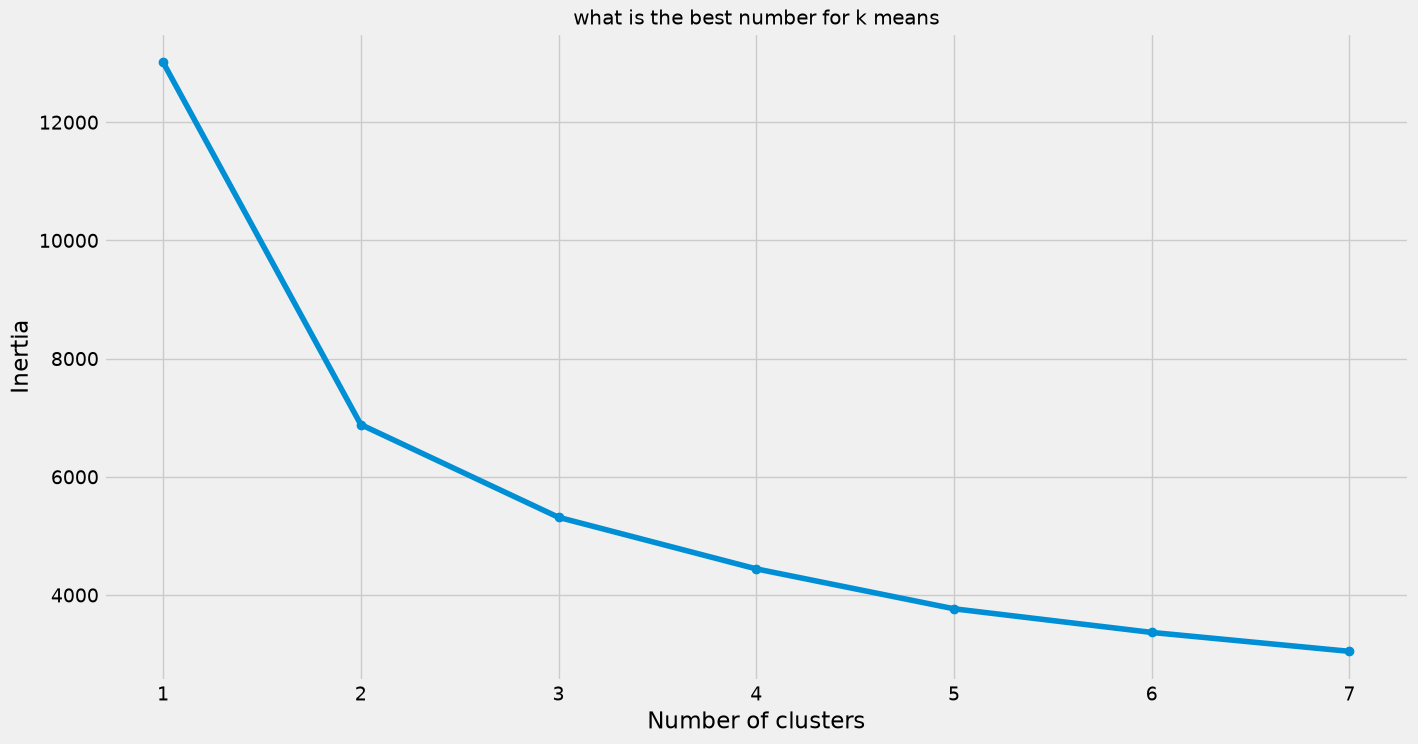

In [38]:
from sklearn.cluster import KMeans

#first : get the best Kmeans
ks = range(1,8)
inertias=[]
for k in ks:
    #crete a KMeans clusters
    kc = KMeans(n_clusters=k,random_state=1)
    kc.fit(rfm_normalized)
    inertias.append(kc.inertia_)

#plot the distribution
f , ax=plt.subplots(figsize=(15, 8))
plt.plot(ks, inertias,'-o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.xticks(ks)
plt.style.use('ggplot')
plt.title("what is the best number for k means")
plt.show()

note that:we choose no.kmeans =3

In [39]:
#clustering 
kc = KMeans(n_clusters=3,random_state=1)
kc.fit(rfm_normalized)

#create a cluuster label column in the original Dataframe
cluster_labels  = kc.labels_

#create average RFM values and size for each cluster:
rfm_rfm_k3 = rfm_rfm.assign(K_cluster = cluster_labels)

#calculate average RFM values and size for each cluster:
rfm_rfm_k3.groupby('K_cluster').agg({'Recency':'mean','Frequency':'mean','MonetaryValue':['mean','count'],}).round(0)

Recency Frequency MonetaryValue      
             mean      mean          mean count
K_cluster                                      
0            69.0      66.0        1183.0  1850
1            13.0     262.0        6610.0   945
2           170.0      15.0         294.0  1543

#### *Snake plots to understand and compare segments*

In [40]:
rfm_normalized = pd.DataFrame(rfm_normalized,index=rfm.index,columns=rfm_rfm.columns)
rfm_normalized['K_cluster'] = kc.labels_
rfm_normalized['General_Segment'] = rfm['General_Segment']
rfm_normalized.reset_index(inplace=True)


#melt the data into a long format so RFM values and metric are stored in 1 Column Each
rfm_melt = pd.melt(rfm_normalized,id_vars=['CustomerID','General_Segment','K_cluster'], value_vars=['Recency','Frequency','MonetaryValue'],
                   var_name='Metric',value_name='Value')
rfm_melt.head()

,CustomerID,General_Segment,K_cluster,Metric,Value
0,12346.0,silver,0,Recency,1.409982
1,12347.0,gold,1,Recency,-2.146578
2,12348.0,silver,0,Recency,0.383648
3,12349.0,gold,0,Recency,-0.574961
4,12350.0,bronze,2,Recency,1.375072


### **Snake plot and Heatmap**

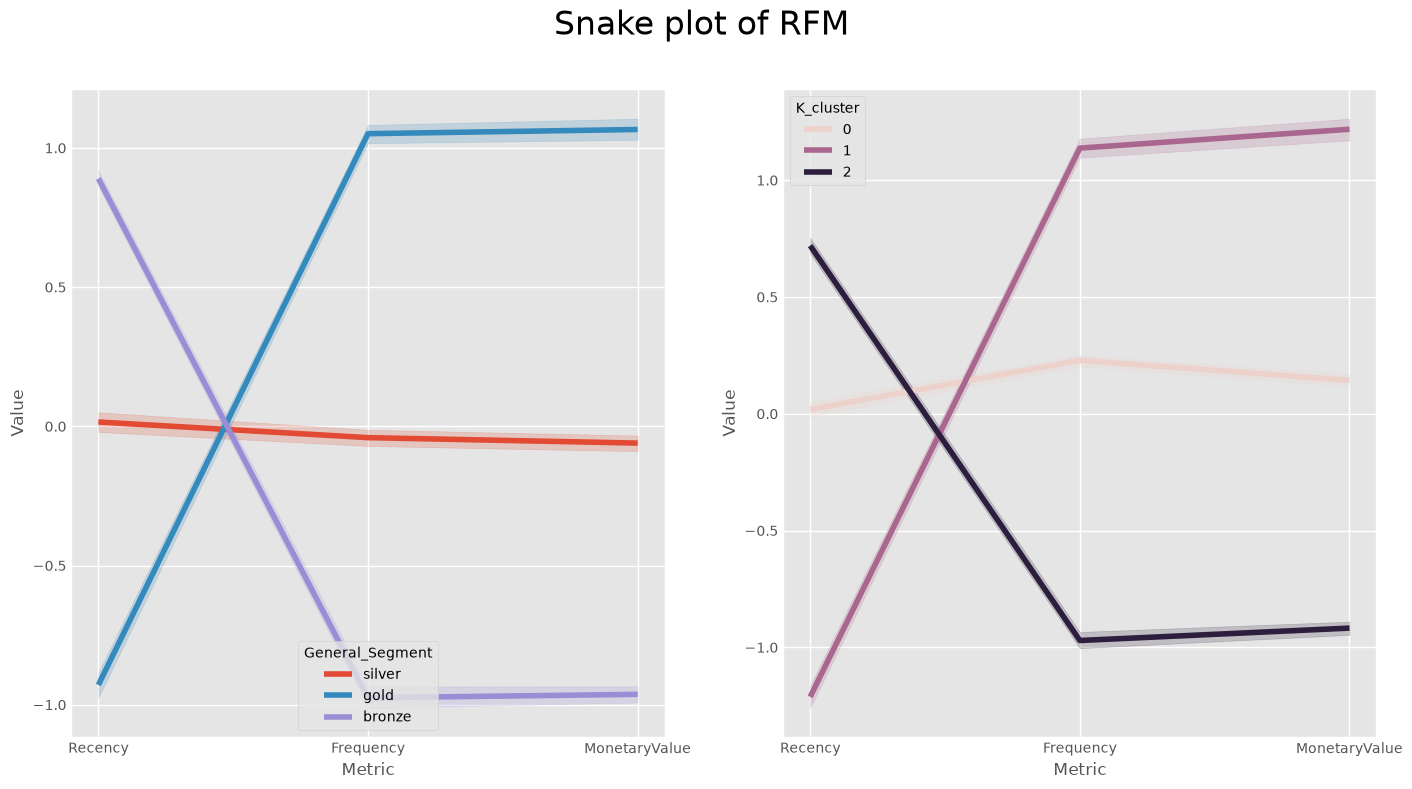

In [41]:

f,(ax1, ax2) = plt.subplots(1, 2 , figsize=(15,8))
sns.lineplot(x = 'Metric', y = 'Value', hue= 'General_Segment',data=rfm_melt,ax=ax1)

# a snake plot eith kmeans
sns.lineplot(x = 'Metric', y = 'Value', hue= 'K_cluster',data=rfm_melt,ax=ax2)
plt.suptitle("Snake plot of RFM", fontsize=24)
plt.show()

In [42]:
#the further a rate is from 0,the more important is for a segment ralative to the total population
cluster_avg = rfm_rfm_k3.groupby(['K_cluster']).mean()
population_avg = rfm_rfm.mean()
relative_imp = cluster_avg / population_avg - 1
relative_imp.round(2)

,Recency,Frequency,MonetaryValue
K_cluster,,,
0,-0.26,-0.27,-0.42
1,-0.86,1.89,2.23
2,0.83,-0.83,-0.86


In [43]:
# the mean in total

total_avg = rfm.iloc[:, 0:3].mean()
#calclate the proportional gap with total mean
cluster_avg = rfm.groupby('General_Segment')[['Recency','Frequency','MonetaryValue']].mean().iloc[:,0:3]
prop_rfm = cluster_avg / total_avg - 1
prop_rfm.round(2)


,Recency,Frequency,MonetaryValue
General_Segment,,,
bronze,1.08,-0.83,-0.87
gold,-0.78,1.49,1.56
silver,-0.22,-0.45,-0.48


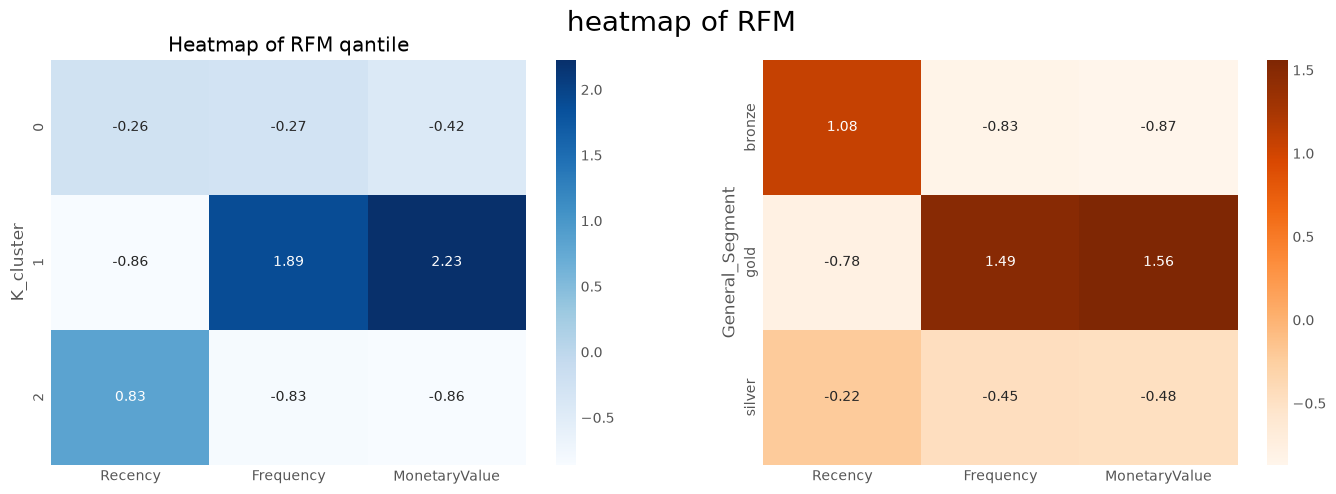

In [44]:
#heatmap with RFM
f, (ax1,ax2) = plt.subplots(1,2, figsize =(15,5))
sns.heatmap(data=relative_imp,annot=True,fmt='.2f',cmap='Blues',ax=ax1)
ax1.set(title="Heatmap of k-Means")

# a snake plot with k-means
sns.heatmap(prop_rfm,annot=True,fmt='.2f',cmap='Oranges',ax=ax2)
ax1.set(title="Heatmap of RFM qantile")

plt.suptitle("heatmap of RFM",fontsize=20) #make title fontsize subtitlle

plt.show()